<a href="https://colab.research.google.com/github/guslimaa777/45419370/blob/main/aula13_decisao_metricas_aluno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 13 – Escolha de métrica, custo dos erros e interpretação para decisão

## Versão do aluno

### Objetivo da aula
Interpretar os resultados dos modelos e propor uma decisão técnica preliminar com base nas métricas e no custo dos erros.

### Instruções
Complete as células indicadas e registre suas interpretações ao longo da atividade.  
Nesta aula, o foco principal é transformar os resultados em **decisão técnica justificada**.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- pré-processamento;
- treino dos classificadores;
- cálculo das métricas.


In [81]:
# Importe a biblioteca pandas usando o apelido pd.
# O pandas será utilizado para trabalhar com tabelas e dados.

# Importe a biblioteca numpy usando o apelido np.
# O numpy será utilizado para operações matemáticas e numéricas.

# Importe matplotlib.pyplot usando o apelido plt.
# O matplotlib será utilizado para criar gráficos.

# Da biblioteca sklearn.model_selection, importe a função train_test_split.
# Ela será utilizada para separar os dados em conjunto de treinamento e conjunto de teste.

# Da biblioteca sklearn.compose, importe ColumnTransformer.
# Ele será utilizado para aplicar tratamentos diferentes às colunas numéricas e às colunas categóricas.

# Da biblioteca sklearn.pipeline, importe Pipeline.
# Ele será utilizado para organizar várias etapas do tratamento dos dados e do modelo em uma sequência.

# Da biblioteca sklearn.preprocessing, importe OneHotEncoder e StandardScaler.
# OneHotEncoder será utilizado para transformar categorias de texto em números.
# StandardScaler será utilizado para padronizar os valores das colunas numéricas.

# Da biblioteca sklearn.impute, importe SimpleImputer.
# Ele será utilizado para preencher valores que estiverem faltando na base de dados.

# Da biblioteca sklearn.linear_model, importe LogisticRegression.
# Ela será utilizada para criar o modelo de Regressão Logística, usado para classificação.

# Da biblioteca sklearn.tree, importe DecisionTreeClassifier.
# Ele será utilizado para criar o modelo de Árvore de Decisão para classificação.

# Da biblioteca sklearn.metrics, importe as métricas e funções que serão utilizadas para avaliar os modelos.
# Importe confusion_matrix para calcular a matriz de confusão.
# Importe ConfusionMatrixDisplay para exibir a matriz de confusão em forma de gráfico.
# Importe accuracy_score para calcular a acurácia do modelo.
# Importe precision_score para calcular a precisão do modelo.
# Importe recall_score para calcular o recall, também chamado de sensibilidade.
# Importe f1_score para calcular a medida F1.
# Importe roc_auc_score para calcular o valor da métrica AUC.
# Importe roc_curve para calcular os pontos necessários para construir a curva ROC.

# Utilize pd.set_option() para configurar a forma como o pandas mostra as colunas das tabelas.
# Dentro dos parênteses, informe 'display.max_columns' como primeira informação.
# Como segunda informação, informe None.
# O valor None faz com que o pandas mostre todas as colunas da tabela,
# sem esconder colunas quando a tabela tiver muitas delas.

In [82]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)

pd.set_option('display.max_columns', None)

## 2. Leitura da base

Leia o arquivo `dados_aula13_decisao_metricas.csv` e exiba as primeiras linhas.


In [83]:
# Complete aqui
df = pd.read_csv('dados_aula13_decisao_metricas.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,horas_operacao_bomba,falha_critica
0,DEC_0001,Linha_A,Manhã,Solvente,50.58,4.02,1.41,82.25,23.21,2.97,3.61,3,280.5,0
1,DEC_0002,Linha_A,Tarde,Acido,42.94,3.93,2.53,55.45,25.69,2.59,2.30,0,334.8,0
2,DEC_0003,Linha_C,Tarde,Acido,49.45,3.85,2.14,73.50,14.31,2.83,5.60,2,451.1,1
3,DEC_0004,Linha_B,Tarde,Base,NaN,3.32,1.46,59.60,18.74,2.19,2.72,1,242.2,0
4,DEC_0005,Linha_B,Manhã,Acido,37.61,3.00,0.44,52.77,22.93,1.95,3.15,1,374.9,0


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas;
- distribuição da variável-alvo.


In [84]:
# Mostre na tela a dimensão da base de dados utilizando print().
# Escreva 'Dimensão da base:' como texto explicativo.
# Depois da vírgula, informe df.shape para mostrar a quantidade de linhas e colunas da base.

# Mostre o texto '\nTipos de dados:' utilizando print().
# O \n faz uma quebra de linha antes do texto para deixar a apresentação mais organizada.

# Mostre os tipos de dados de todas as colunas utilizando print(df.dtypes).
# O comando df.dtypes informa se cada coluna possui números, textos ou outro tipo de dado.

# Mostre o texto '\nValores faltantes:' utilizando print().
# O \n faz uma quebra de linha antes do texto.

# Verifique a quantidade de valores faltantes em cada coluna utilizando df.isna().sum().
# O df.isna() identifica quais células estão vazias.
# O .sum() conta quantas células vazias existem em cada coluna.
# Utilize print() para mostrar esse resultado na tela.

# Mostre o texto '\nDuplicatas:' utilizando print().
# O \n faz uma quebra de linha antes do texto.

# Verifique a quantidade de linhas duplicadas utilizando df.duplicated().sum().
# O df.duplicated() identifica as linhas que estão repetidas.
# O .sum() conta quantas linhas duplicadas foram encontradas.
# Utilize print() para mostrar a quantidade encontrada.

# Mostre o texto '\nDistribuição da variável-alvo:' utilizando print().
# A variável-alvo é a coluna que queremos prever no modelo.
# Neste exercício, a variável-alvo é a coluna chamada 'falha_critica'.

# Mostre a quantidade de registros de cada classe da variável 'falha_critica'.
# Para isso, selecione a coluna usando df['falha_critica'].
# Depois utilize .value_counts() para contar quantas vezes cada valor aparece.
# Utilize print() para mostrar o resultado na tela.

In [85]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())
print('\nDistribuição da variável-alvo:')
print(df['falha_critica'].value_counts())

Dimensão da base: (392, 14)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
erro_vazao_pct          float64
leituras_invalidas        int64
horas_operacao_bomba    float64
falha_critica             int64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 8
temperatura_c           8
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        8
erro_vazao_pct          0
leituras_invalidas      0
horas_operacao_bomba    0
falha_critica           0
dtype: int64

Duplicatas: 12

Distribuição da variável-alvo:
falha_critica
0    329
1     63
Name: count, dty

**Registro do aluno:**  
-  
-  
-  


## 4. Visualização do desbalanceamento

Calcule a distribuição da variável-alvo e crie um gráfico de barras.


In [86]:
# Crie uma variável chamada dist para armazenar a quantidade de registros
# de cada classe da variável 'falha_critica'.
# Primeiro, selecione a coluna 'falha_critica' utilizando df['falha_critica'].
# Depois, use .value_counts() para contar quantas vezes cada classe aparece.
# Em seguida, use .sort_index() para colocar as classes em ordem crescente:
# primeiro 0 e depois 1.

# Substitua os nomes dos índices da tabela dist por nomes mais fáceis de entender.
# Para isso, utilize dist.index =.
# Coloque uma lista com dois textos, exatamente nesta ordem:
# 'Sem falha crítica (0)' para representar a classe 0.
# 'Falha crítica (1)' para representar a classe 1.

# Na última linha, escreva apenas dist para exibir a tabela na tela.
# A tabela mostrará a quantidade de registros sem falha crítica e com falha crítica.

In [87]:
# Complete aqui
dist = df['falha_critica'].value_counts().sort_index()
dist.index = ['Sem falha crítica (0)', 'Falha crítica (1)']
dist

,count
Sem falha crítica (0),329
Falha crítica (1),63


In [88]:
# Crie uma figura para o gráfico utilizando a função plt.figure().
# Dentro dos parênteses, informe figsize=(7,4) para definir o tamanho da figura.

# Crie um gráfico de barras utilizando a função plt.bar().
# No primeiro argumento, coloque dist.index para usar os nomes das classes
# como valores do eixo X.
# No segundo argumento, coloque dist.values para usar as quantidades
# de cada classe como altura das barras.

# Defina o título do gráfico utilizando a função plt.title().
# Escreva exatamente: 'Distribuição da variável-alvo'

# Identifique o eixo Y utilizando a função plt.ylabel().
# Escreva 'Quantidade' para indicar que o eixo mostra o número de registros.

# Utilize plt.tight_layout() para ajustar automaticamente os espaços do gráfico.

# Utilize plt.show() para exibir o gráfico na tela.

In [89]:
# Gere o gráfico aqui
# Complete aqui
dist = df['falha_critica'].value_counts().sort_index()
dist.index = ['Sem falha crítica (0)', 'Falha crítica (1)']
dist

,count
Sem falha crítica (0),329
Falha crítica (1),63


## 5. Limpeza básica

Remova as duplicatas da base.


In [90]:
# Remova as linhas duplicadas da tabela utilizando a função df.drop_duplicates().
# O comando identifica registros que estão repetidos e mantém apenas uma ocorrência de cada registro.
#
# Depois de remover as duplicatas, utilize .copy() para criar uma cópia independente
# do resultado e atribua novamente esse resultado à variável df.
#
# Em seguida, utilize print() para mostrar uma mensagem na tela.
# Escreva exatamente: 'Dimensão após remoção de duplicatas:'
# Depois da mensagem, informe df.shape para mostrar a quantidade de linhas e colunas
# que a tabela possui depois da remoção das duplicatas.

In [91]:
# Complete aqui
df = df.drop_duplicates().copy()
print('Dimensão após remoção de duplicatas:', df.shape)

Dimensão após remoção de duplicatas: (380, 14)


## 6. Definição de X e y

Separe:
- `X`: variáveis de entrada;
- `y`: variável-alvo binária `falha_critica`.

**Pergunta:**  
Por que `id_registro` não deve ser usado como preditora?


In [92]:
# Crie a variável X para armazenar as variáveis que serão utilizadas como entrada do modelo.
# Para isso, utilize df.drop().
# Dentro de columns=[ ], informe as colunas que não devem fazer parte das entradas:
# 'id_registro' e 'falha_critica'.
# A coluna 'id_registro' é apenas um identificador do registro.
# A coluna 'falha_critica' é a variável que queremos prever e, por isso, não deve ficar em X.
#
# Crie a variável y para armazenar a variável-alvo que o modelo deverá prever.
# Para isso, selecione a coluna 'falha_critica' da tabela df.
#
# Utilize print() para mostrar o tamanho de X na tela.
# Dentro de print(), informe X.shape.
# O resultado mostrará a quantidade de linhas e colunas das variáveis de entrada.
#
# Utilize outro print() para mostrar o tamanho de y na tela.
# Dentro de print(), informe y.shape.
# O resultado mostrará a quantidade de registros da variável que será prevista.

In [93]:
# Complete aqui
# Complete aqui
X = df.drop(columns=['id_registro', 'falha_critica'])
y = df['falha_critica']

print(X.shape)
print(y.shape)

(380, 12)
(380,)


**Resposta do aluno:**  


## 7. Divisão em treino e teste

Faça a divisão usando `stratify=y`.


In [94]:
# Separe os dados em quatro partes utilizando a função train_test_split().
# Essa função dividirá os dados em conjunto de treinamento e conjunto de teste.
#
# Informe X como primeiro argumento.
# X contém as variáveis de entrada que serão utilizadas pelo modelo.
#
# Informe y como segundo argumento.
# y contém a variável-alvo 'falha_critica' que o modelo deverá aprender a prever.
#
# Informe test_size=0.25.
# Isso significa que 25% dos dados serão separados para teste
# e os outros 75% serão utilizados para treinamento.
#
# Informe random_state=42.
# Esse valor faz com que a divisão seja sempre reproduzida da mesma maneira
# quando o código for executado novamente.
#
# Informe stratify=y.
# Esse parâmetro faz com que a proporção das classes da variável 'falha_critica'
# seja mantida tanto no conjunto de treinamento quanto no conjunto de teste.
# Isso é importante porque estamos trabalhando com um problema de classificação.
#
# Armazene os quatro resultados da divisão nas seguintes variáveis:
# X_train → dados de entrada utilizados para treinar o modelo.
# X_test → dados de entrada utilizados para testar o modelo.
# y_train → valores reais da variável-alvo usados no treinamento.
# y_test → valores reais da variável-alvo usados no teste.
#
# Utilize print() para mostrar o tamanho dos dados de treinamento.
# Escreva a mensagem 'Treino:' e, depois, informe X_train.shape e y_train.shape.
#
# Utilize outro print() para mostrar o tamanho dos dados de teste.
# Escreva a mensagem 'Teste:' e, depois, informe X_test.shape e y_test.shape.
#
# Utilize print() para mostrar a mensagem:
# '\nDistribuição em y_train:'
# O \n faz com que seja criada uma linha em branco antes da mensagem.
#
# Utilize y_train.value_counts() para contar quantos registros existem
# em cada classe da variável-alvo dentro do conjunto de treinamento.
#
# Utilize print() para mostrar a mensagem:
# '\nDistribuição em y_test:'
# Novamente, o \n cria uma linha em branco antes da mensagem.
#
# Utilize y_test.value_counts() para contar quantos registros existem
# em cada classe da variável-alvo dentro do conjunto de teste.
#
# Ao final, será possível verificar se a quantidade de exemplos das classes
# 0 e 1 ficou proporcional entre treinamento e teste.

In [95]:
# Complete aqui
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print('Treino:', X_train.shape, y_train.shape)
print('Teste:', X_test.shape, y_test.shape)
print('\nDistribuição em y_train:')
print(y_train.value_counts())
print('\nDistribuição em y_test:')
print(y_test.value_counts())

Treino: (285, 12) (285,)
Teste: (95, 12) (95,)

Distribuição em y_train:
falha_critica
0    239
1     46
Name: count, dtype: int64

Distribuição em y_test:
falha_critica
0    80
1    15
Name: count, dtype: int64


## 8. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [96]:
# Identifique quais colunas da tabela X são numéricas.
# Para isso, utilize X.select_dtypes().
# Dentro de include=[ ], informe 'int64' e 'float64' para selecionar colunas numéricas.
# Depois, utilize .columns.tolist() para obter os nomes dessas colunas em formato de lista.
# Armazene essa lista na variável colunas_numericas.
#
# Identifique quais colunas da tabela X são categóricas.
# Utilize novamente X.select_dtypes().
# Dentro de include=[ ], informe 'object' para selecionar as colunas que contêm textos ou categorias.
# Depois, utilize .columns.tolist() para transformar os nomes das colunas em uma lista.
# Armazene essa lista na variável colunas_categoricas.
#
# Crie um pipeline chamado transformador_numerico utilizando Pipeline().
# Dentro de steps=[ ], informe duas etapas.
#
# Na primeira etapa, utilize o nome 'imputer' e a função SimpleImputer().
# Dentro de SimpleImputer(), informe strategy='median'.
# Isso fará com que valores numéricos que estiverem faltando sejam preenchidos
# utilizando a mediana da respectiva coluna.
#
# Na segunda etapa, utilize o nome 'scaler' e a função StandardScaler().
# O StandardScaler() será utilizado para padronizar os valores das colunas numéricas,
# colocando as variáveis em uma escala comparável.
#
# Crie um segundo pipeline chamado transformador_categorico utilizando Pipeline().
# Dentro de steps=[ ], informe duas etapas.
#
# Na primeira etapa, utilize o nome 'imputer' e a função SimpleImputer().
# Dentro de SimpleImputer(), informe strategy='most_frequent'.
# Isso fará com que valores categóricos que estiverem faltando sejam preenchidos
# utilizando o valor que aparece com maior frequência na coluna.
#
# Na segunda etapa, utilize o nome 'onehot' e a função OneHotEncoder().
# Dentro de OneHotEncoder(), informe handle_unknown='ignore'.
# Isso permite que o modelo encontre uma categoria no conjunto de teste
# que não apareceu durante o treinamento sem gerar um erro.
#
# Crie a variável preprocessador utilizando ColumnTransformer().
# Dentro de transformers=[ ], informe duas etapas de transformação.
#
# Na primeira etapa, utilize o nome 'num'.
# Depois, informe transformador_numerico para indicar qual tratamento será aplicado.
# Por último, informe colunas_numericas para indicar em quais colunas esse tratamento será aplicado.
#
# Na segunda etapa, utilize o nome 'cat'.
# Depois, informe transformador_categorico para indicar qual tratamento será aplicado.
# Por último, informe colunas_categoricas para indicar em quais colunas esse tratamento será aplicado.
#
# Dessa forma, o preprocessador aplicará automaticamente:
# - preenchimento pela mediana e padronização nas colunas numéricas;
# - preenchimento pela categoria mais frequente e One-Hot Encoding nas colunas categóricas.

In [97]:
# Complete aqui
colunas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

## 9. Criação dos classificadores

Crie:
- um modelo de Regressão Logística;
- um modelo de Árvore de Decisão Classificadora.


In [98]:
# Crie um pipeline chamado modelo_logistico utilizando a função Pipeline().
# Dentro de steps=[ ], informe duas etapas.
#
# Na primeira etapa, use o nome 'preprocessador'.
# Depois dos dois-pontos, informe a variável preprocessador.
# Essa etapa será responsável por preparar os dados antes do treinamento.
#
# Na segunda etapa, use o nome 'modelo'.
# Depois dos dois-pontos, utilize a função LogisticRegression().
# Dentro dos parênteses, informe max_iter=1000.
# Esse parâmetro permite que a Regressão Logística faça até 1000 iterações
# durante o treinamento para encontrar uma solução.
#
# Crie outro pipeline chamado modelo_arvore utilizando a função Pipeline().
# Novamente, dentro de steps=[ ], informe duas etapas.
#
# Na primeira etapa, use o nome 'preprocessador'.
# Depois dos dois-pontos, informe a variável preprocessador.
#
# Na segunda etapa, use o nome 'modelo'.
# Depois dos dois-pontos, utilize a função DecisionTreeClassifier().
# Dentro dos parênteses, informe max_depth=5.
# Esse parâmetro limita a profundidade da árvore a no máximo 5 níveis.
#
# Ainda dentro de DecisionTreeClassifier(), informe random_state=42.
# Esse parâmetro permite reproduzir o mesmo resultado quando o modelo for treinado novamente.
#
# Ao final, você terá dois pipelines:
# modelo_logistico → preprocessamento + Regressão Logística.
# modelo_arvore → preprocessamento + Árvore de Decisão.

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modelo_logistico = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LogisticRegression(max_iter=1000))
])

modelo_arvore = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeClassifier(max_depth=5, random_state=42))
])

## 10. Treino dos modelos

Treine os dois classificadores.


In [100]:
# Treine o modelo de Regressão Logística utilizando a função .fit().
# Depois do nome modelo_logistico, escreva .fit().
# Dentro dos parênteses, informe X_train e y_train.
# X_train contém os dados de entrada utilizados no treinamento.
# y_train contém os valores reais da variável-alvo utilizados no treinamento.
#
# Treine o modelo de Árvore de Decisão da mesma forma.
# Depois do nome modelo_arvore, escreva .fit().
# Dentro dos parênteses, informe X_train e y_train.
#
# O método .fit() faz o modelo aprender os padrões existentes nos dados de treinamento.
# Como os modelos estão dentro de pipelines, o pré-processamento definido anteriormente
# será executado automaticamente antes do treinamento de cada modelo.
#
# Utilize print() para mostrar uma mensagem informando que os dois modelos
# foram treinados com sucesso.
# Escreva exatamente:
# 'Modelos treinados com sucesso.'

In [101]:
# Complete aqui
modelo_logistico.fit(X_train, y_train)
modelo_arvore.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 11. Predições e probabilidades

Gere:
- classes previstas;
- probabilidades da classe positiva.


In [102]:
# Crie a variável pred_log para armazenar as previsões da Regressão Logística.
# Utilize a função .predict() do modelo modelo_logistico.
# Dentro dos parênteses, informe X_test.
# O modelo utilizará os dados de teste para prever a classe de cada registro.
#
# Crie a variável pred_tree para armazenar as previsões da Árvore de Decisão.
# Utilize a função .predict() do modelo modelo_arvore.
# Dentro dos parênteses, informe X_test.
#
# Crie a variável proba_log para armazenar a probabilidade prevista
# pela Regressão Logística para a classe 1, que representa 'Falha crítica'.
# Para isso, utilize a função .predict_proba() do modelo modelo_logistico.
# Dentro dos parênteses, informe X_test.
# Depois, utilize [:, 1] para selecionar a coluna referente à classe 1.
#
# Crie a variável proba_tree para armazenar a probabilidade prevista
# pela Árvore de Decisão para a classe 1, que representa 'Falha crítica'.
# Utilize .predict_proba() do modelo modelo_arvore.
# Dentro dos parênteses, informe X_test.
# Depois, utilize [:, 1] para selecionar somente as probabilidades da classe 1.
#
# A diferença é:
# .predict() retorna a classe prevista pelo modelo, como 0 ou 1.
# .predict_proba() retorna as probabilidades de cada classe.
# O [:, 1] seleciona somente a probabilidade da classe 1.

In [103]:
# Complete aqui
pred_log = modelo_logistico.predict(X_test)
pred_tree = modelo_arvore.predict(X_test)

proba_log = modelo_logistico.predict_proba(X_test)[:, 1]
proba_tree = modelo_arvore.predict_proba(X_test)[:, 1]

## 12. Matrizes de confusão

Calcule as matrizes de confusão e faça a visualização.


In [104]:
# Crie a variável cm_log para armazenar a matriz de confusão da Regressão Logística.
# Utilize a função confusion_matrix().
# Dentro dos parênteses, informe primeiro y_test, que contém os valores reais.
# Depois, informe pred_log, que contém as previsões da Regressão Logística.
#
# Crie a variável cm_tree para armazenar a matriz de confusão da Árvore de Decisão.
# Utilize novamente a função confusion_matrix().
# Dentro dos parênteses, informe primeiro y_test, que contém os valores reais.
# Depois, informe pred_tree, que contém as previsões da Árvore de Decisão.
#
# Utilize print() para exibir o texto:
# 'Matriz de confusão - Regressão Logística'
#
# Na linha seguinte, utilize print(cm_log) para mostrar a matriz de confusão
# calculada para a Regressão Logística.
#
# Utilize outro print() para exibir o texto:
# '\nMatriz de confusão - Árvore de Decisão'
# O \n cria uma linha em branco antes do texto.
#
# Na linha seguinte, utilize print(cm_tree) para mostrar a matriz de confusão
# calculada para a Árvore de Decisão.
#
# A matriz de confusão permite comparar as classes reais de y_test
# com as classes previstas pelos modelos.
# Ela será utilizada posteriormente para identificar:
# Verdadeiros Positivos (TP), Falsos Positivos (FP),
# Verdadeiros Negativos (TN) e Falsos Negativos (FN).

In [105]:
# Complete aqui
from sklearn.metrics import confusion_matrix
cm_log = (y_test, pred_log)
cm_tree = confusion_matrix(y_test, pred_tree)

print('Matriz de confusão - Regressão Logística')
print(confusion_matrix(*cm_log))
print('\nMatriz de confusão - Árvore de Decisão')
print(cm_tree)

Matriz de confusão - Regressão Logística
[[79  1]
 [ 7  8]]

Matriz de confusão - Árvore de Decisão
[[72  8]
 [15  0]]


In [106]:
# Crie uma figura com dois gráficos lado a lado utilizando plt.subplots().
# Informe 1 para o número de linhas e 2 para o número de colunas.
# Utilize figsize=(10,4) para definir o tamanho total da figura.
# Armazene a figura na variável fig e os dois espaços dos gráficos na variável axes.
#
# Exiba a matriz de confusão da Regressão Logística utilizando ConfusionMatrixDisplay().
# Dentro dos parênteses, informe cm_log, que contém a matriz de confusão desse modelo.
# Depois, utilize .plot() e informe ax=axes[0] para colocar o gráfico no primeiro espaço.
# Informe colorbar=False para não exibir a barra de cores ao lado da matriz.
#
# Defina o título do primeiro gráfico utilizando axes[0].set_title().
# Escreva exatamente: 'Regressão Logística'
#
# Exiba a matriz de confusão da Árvore de Decisão utilizando ConfusionMatrixDisplay().
# Dentro dos parênteses, informe cm_tree, que contém a matriz de confusão desse modelo.
# Depois, utilize .plot() e informe ax=axes[1] para colocar o gráfico no segundo espaço.
# Informe colorbar=False para não exibir a barra de cores.
#
# Defina o título do segundo gráfico utilizando axes[1].set_title().
# Escreva exatamente: 'Árvore de Decisão'
#
# Utilize plt.tight_layout() para ajustar automaticamente os espaços entre os dois gráficos.
#
# Utilize plt.show() para exibir a figura completa na tela.
#
# Ao final, serão exibidas as duas matrizes de confusão lado a lado,
# permitindo comparar visualmente os resultados dos dois modelos.

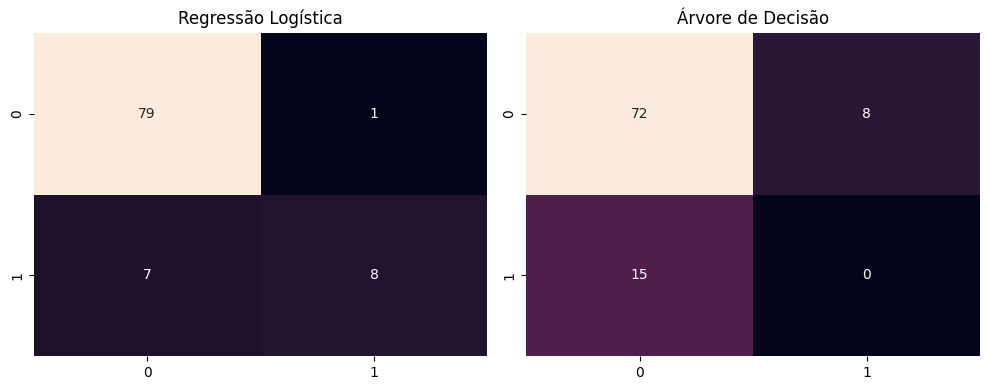

In [107]:

# Gere a visualização aqui
fig, axes = plt.subplots(1, 2, figsize=(10,4))

sns.heatmap(
    confusion_matrix(y_test, pred_log),
    annot=True, fmt='d', ax=axes[0], cbar=False
)
axes[0].set_title('Regressão Logística')

sns.heatmap(
    confusion_matrix(y_test, pred_tree),
    annot=True, fmt='d', ax=axes[1], cbar=False
)
axes[1].set_title('Árvore de Decisão')

plt.tight_layout()
plt.show()

## 13. Cálculo das métricas

Calcule:
- acurácia;
- precisão;
- recall;
- F1-score;
- AUC.


In [108]:
# Crie uma tabela chamada metricas utilizando a função pd.DataFrame().
# Dentro das chaves { }, crie uma coluna chamada 'Modelo'.
# Informe uma lista com os nomes dos dois modelos:
# 'Regressão Logística' e 'Árvore de Decisão'.
#
# Crie a coluna 'Acurácia'.
# Para a Regressão Logística, utilize accuracy_score(y_test, pred_log).
# Essa função compara os valores reais de y_test com as previsões pred_log.
# Para a Árvore de Decisão, utilize accuracy_score(y_test, pred_tree).
#
# Crie a coluna 'Precisão'.
# Para a Regressão Logística, utilize precision_score(y_test, pred_log, zero_division=0).
# Para a Árvore de Decisão, utilize precision_score(y_test, pred_tree, zero_division=0).
# O parâmetro zero_division=0 define que o resultado será 0 caso não seja possível
# calcular a precisão por ausência de exemplos em alguma classe.
#
# Crie a coluna 'Recall'.
# Para a Regressão Logística, utilize recall_score(y_test, pred_log, zero_division=0).
# Para a Árvore de Decisão, utilize recall_score(y_test, pred_tree, zero_division=0).
# O Recall mede quantos dos casos positivos reais foram identificados corretamente.
#
# Crie a coluna 'F1-score'.
# Para a Regressão Logística, utilize f1_score(y_test, pred_log, zero_division=0).
# Para a Árvore de Decisão, utilize f1_score(y_test, pred_tree, zero_division=0).
# O F1-score combina Precisão e Recall em uma única métrica.
#
# Crie a coluna 'AUC'.
# Para a Regressão Logística, utilize roc_auc_score(y_test, proba_log).
# Para a Árvore de Decisão, utilize roc_auc_score(y_test, proba_tree).
# Nesse cálculo, utilize as probabilidades da classe 1 armazenadas anteriormente
# em proba_log e proba_tree, e não as classes previstas em pred_log e pred_tree.
#
# Depois de fechar o pd.DataFrame(), utilize .round(4).
# Isso fará com que os valores das métricas sejam apresentados com 4 casas decimais.
#
# Armazene o resultado completo na variável metricas.
#
# Na última linha, escreva apenas metricas para exibir a tabela na tela.
# A tabela apresentará Acurácia, Precisão, Recall, F1-score e AUC
# para os dois modelos.

In [109]:
metricas = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão'],
    'Acurácia': [
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_tree)
    ],
    'Precisão': [
        precision_score(y_test, pred_log, zero_division=0),
        precision_score(y_test, pred_tree, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, pred_log, zero_division=0),
        recall_score(y_test, pred_tree, zero_division=0)
    ],
    'F1-Score': [
        f1_score(y_test, pred_log, zero_division=0),
        f1_score(y_test, pred_tree, zero_division=0)
    ],
    'AUC': [
        roc_auc_score(y_test, proba_log),
        roc_auc_score(y_test, proba_tree)
    ]
}).round(4)

metricas

,Modelo,Acurácia,Precisão,Recall,F1-Score,AUC
0,Regressão Logística,0.9158,0.8889,0.5333,0.6667,0.9092
1,Árvore de Decisão,0.7579,0.0000,0.0000,0.0000,0.5254


## 14. Visualização comparativa das métricas

Crie gráficos comparando os dois modelos.


In [110]:
# Complete aqui
metricas_plot = metricas.set_index('Modelo')

In [111]:
# Crie uma variável chamada metricas_plot.
# Utilize metricas.set_index('Modelo') para transformar a coluna 'Modelo'
# no índice da tabela.
# Isso facilitará a criação dos gráficos utilizando os nomes dos modelos no eixo X.
#
# Crie um laço de repetição utilizando for.
# Na variável chamada coluna, percorra uma lista contendo exatamente:
# 'Acurácia', 'Precisão', 'Recall', 'F1-score' e 'AUC'.
# Dessa forma, será criado um gráfico separado para cada uma dessas métricas.
#
# Dentro do for, crie uma nova figura utilizando plt.figure().
# Informe figsize=(7,4) para definir o tamanho do gráfico.
#
# Crie um gráfico de barras utilizando plt.bar().
# No primeiro argumento, informe metricas_plot.index para utilizar
# os nomes dos modelos no eixo X.
# No segundo argumento, informe metricas_plot[coluna] para utilizar
# os valores da métrica que está sendo analisada naquele momento.
#
# Defina o título utilizando plt.title().
# Utilize uma f-string com o texto:
# f'Comparação de {coluna}'
# Assim, o nome da métrica será inserido automaticamente no título.
#
# Defina os limites do eixo Y utilizando plt.ylim().
# Informe 0 como limite inferior e 1.05 como limite superior.
# Isso cria uma escala de 0 até 1.05 para facilitar a comparação das métricas.
#
# Identifique o eixo Y utilizando plt.ylabel().
# Informe coluna para que o nome da métrica atual apareça no eixo.
#
# Utilize plt.tight_layout() para ajustar automaticamente os espaços do gráfico.
#
# Utilize plt.show() para exibir o gráfico na tela.
#
# Como o código está dentro do for, será gerado um gráfico para cada métrica:
# Acurácia, Precisão, Recall, F1-score e AUC.

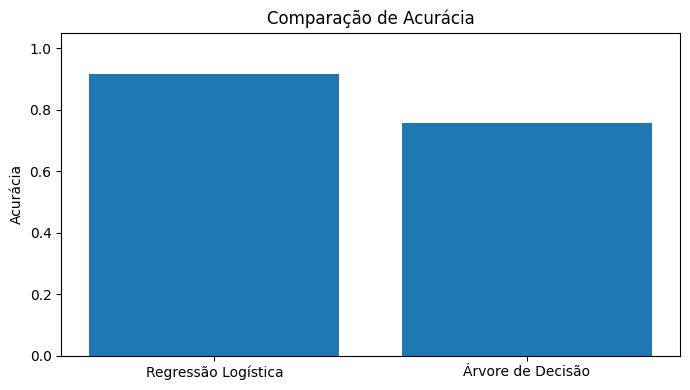

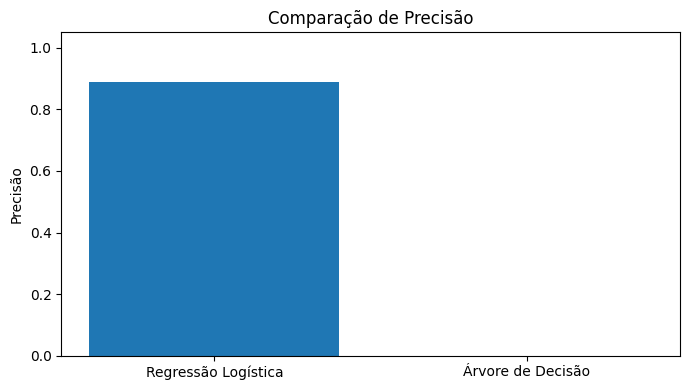

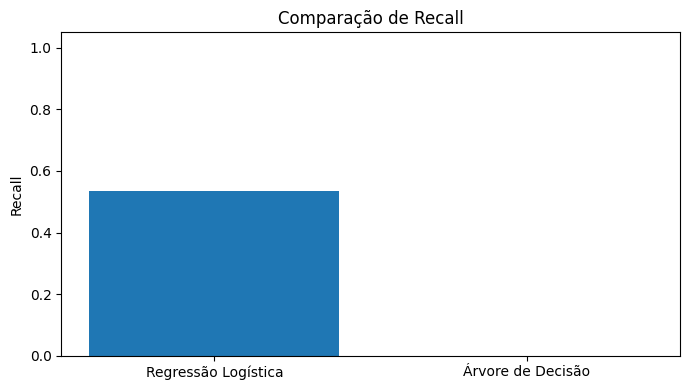

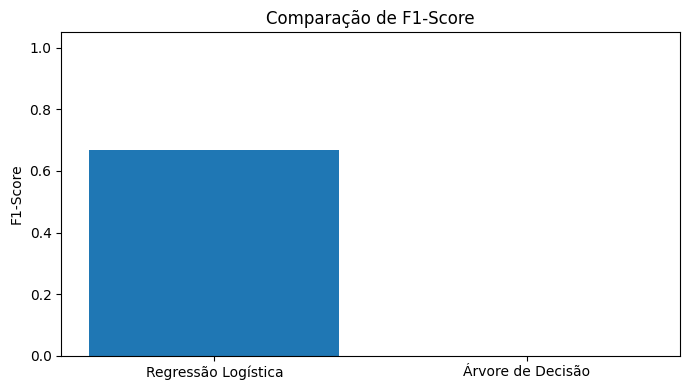

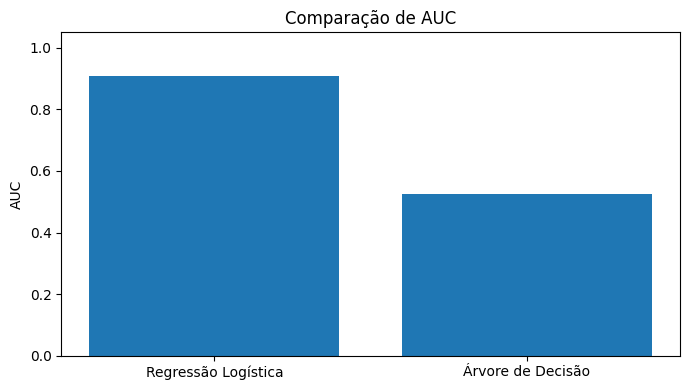

In [112]:
# Gere os gráficos aqui para Acurácia, Precisão, Recall, F1-score e AUC
import matplotlib.pyplot as plt

metricas_plot = metricas.set_index('Modelo')

for coluna in ['Acurácia', 'Precisão', 'Recall', 'F1-Score', 'AUC']:
    plt.figure(figsize=(7, 4))
    plt.bar(metricas_plot.index, metricas_plot[coluna])
    plt.title(f'Comparação de {coluna}')
    plt.ylim(0, 1.05)
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()


## 15. Curva ROC e AUC

Calcule a curva ROC e monte o gráfico comparativo.


In [113]:
# Calcule os pontos da Curva ROC para a Regressão Logística.
# Utilize a função roc_curve().
# Dentro dos parênteses, informe y_test e proba_log.
# A função retornará três informações:
# FPR, TPR e os thresholds utilizados para construir a curva.
# Armazene esses três resultados nas variáveis fpr_log, tpr_log e _.
# O símbolo _ será utilizado porque não precisamos dos thresholds neste gráfico.
#
# Faça o mesmo para a Árvore de Decisão.
# Utilize roc_curve(y_test, proba_tree).
# Armazene os resultados nas variáveis fpr_tree, tpr_tree e _.
#
# Crie uma figura utilizando plt.figure().
# Informe figsize=(7,5) para definir o tamanho do gráfico.
#
# Desenhe a Curva ROC da Regressão Logística utilizando plt.plot().
# No eixo X, utilize fpr_log.
# No eixo Y, utilize tpr_log.
# Utilize label= para criar o texto que aparecerá na legenda.
# Dentro do texto, escreva 'Regressão Logística (AUC = ' e depois calcule o AUC
# utilizando roc_auc_score(y_test, proba_log).
# Utilize :.3f para mostrar o valor da AUC com 3 casas decimais.
#
# Desenhe a Curva ROC da Árvore de Decisão utilizando plt.plot().
# No eixo X, utilize fpr_tree.
# No eixo Y, utilize tpr_tree.
# Na legenda, escreva 'Árvore de Decisão (AUC = ' e calcule o AUC
# utilizando roc_auc_score(y_test, proba_tree).
# Utilize :.3f para mostrar o valor da AUC com 3 casas decimais.
#
# Crie a linha de referência da Curva ROC utilizando plt.plot().
# No eixo X, informe [0, 1].
# No eixo Y, informe [0, 1].
# Utilize linestyle='--' para deixar essa linha tracejada.
# Essa linha representa uma classificação sem capacidade de discriminação.
#
# Identifique o eixo X utilizando plt.xlabel().
# Escreva exatamente: 'Taxa de Falsos Positivos'
#
# Identifique o eixo Y utilizando plt.ylabel().
# Escreva exatamente: 'Taxa de Verdadeiros Positivos'
#
# Defina o título utilizando plt.title().
# Escreva exatamente: 'Curva ROC'
#
# Exiba a legenda utilizando plt.legend().
# Ela mostrará as duas curvas e os respectivos valores de AUC.
#
# Utilize plt.tight_layout() para ajustar os espaços do gráfico.
#
# Por fim, utilize plt.show() para exibir a Curva ROC na tela.

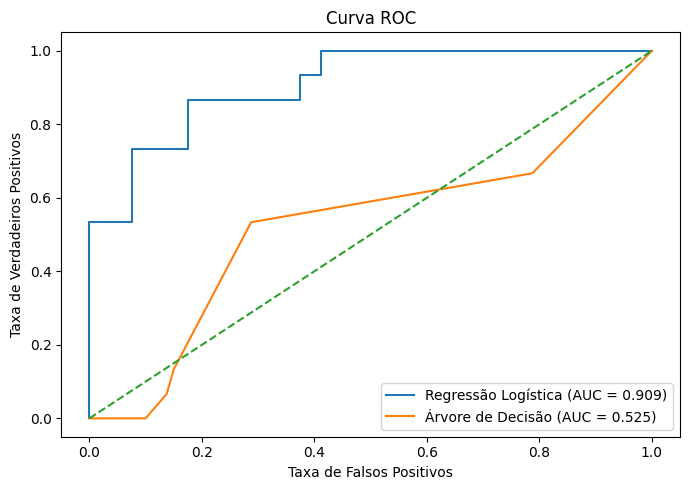

In [114]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_log, tpr_log, _ = roc_curve(y_test, proba_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, proba_tree)

plt.figure(figsize=(7,5))

plt.plot(
    fpr_log, tpr_log,
    label=f'Regressão Logística (AUC = {roc_auc_score(y_test, proba_log):.3f})'
)

plt.plot(
    fpr_tree, tpr_tree,
    label=f'Árvore de Decisão (AUC = {roc_auc_score(y_test, proba_tree):.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

##***16. Estudo de custo dos erros***
Agora faremos um exercício de decisão.  
Suponha o seguinte cenário industrial:

- **Falso positivo (FP)**: gera inspeção desnecessária e custo operacional de **R$ 5.000**

- **Falso negativo (FN)**: deixa de sinalizar uma falha crítica e pode gerar perda de produção e risco técnico, com custo estimado de **R$ 150.000**

###***Objetivo***
Traduzir os erros do modelo em impacto financeiro aproximado.

Considere o cenário:
- **Falso positivo (FP)**: custo de R$ 5.000

- **Falso negativo (FN)**: custo de R$ 150.000

Calcule o custo estimado dos erros para cada modelo.


In [115]:
# Crie uma função chamada custo_erros().
# A função receberá três informações:
# cm → matriz de confusão do modelo.
# custo_fp=5000 → custo estimado de cada Falso Positivo.
# custo_fn=150000 → custo estimado de cada Falso Negativo.
#
# Dentro da função, utilize cm.ravel() para separar os quatro valores
# da matriz de confusão.
# Armazene os valores, nesta ordem, nas variáveis:
# tn → Verdadeiros Negativos.
# fp → Falsos Positivos.
# fn → Falsos Negativos.
# tp → Verdadeiros Positivos.
#
# Crie a variável custo_total.
# Calcule o custo dos erros multiplicando:
# quantidade de Falsos Positivos × custo de cada Falso Positivo
# +
# quantidade de Falsos Negativos × custo de cada Falso Negativo.
# Utilize a fórmula:
# fp * custo_fp + fn * custo_fn
#
# Utilize return para retornar três informações:
# fp, fn e custo_total.
#
# Calcule os erros da Regressão Logística.
# Utilize a função custo_erros() e informe cm_log como argumento.
# Armazene os três resultados nas variáveis:
# fp_log, fn_log e custo_log.
# Como os valores padrão da função já são 5000 para FP e 150000 para FN,
# não é necessário informar esses valores novamente.
#
# Calcule os erros da Árvore de Decisão.
# Utilize a função custo_erros() e informe cm_tree como argumento.
# Armazene os resultados nas variáveis:
# fp_tree, fn_tree e custo_tree.
#
# Crie uma tabela chamada custos utilizando pd.DataFrame().
# Dentro das chaves { }, crie a coluna 'Modelo'.
# Informe uma lista contendo:
# 'Regressão Logística' e 'Árvore de Decisão'.
#
# Crie a coluna 'Falsos Positivos'.
# Informe a lista [fp_log, fp_tree].
#
# Crie a coluna 'Falsos Negativos'.
# Informe a lista [fn_log, fn_tree].
#
# Crie a coluna 'Custo estimado (R$)'.
# Informe a lista [custo_log, custo_tree].
#
# Na última linha, escreva apenas custos para exibir a tabela na tela.
#
# A tabela mostrará, para cada modelo:
# a quantidade de Falsos Positivos,
# a quantidade de Falsos Negativos
# e o custo estimado associado a esses erros.

In [116]:
# Complete aqui
import pandas as pd
from sklearn.metrics import confusion_matrix

def custo_erros(cm, custo_fp=5000, custo_fn=150000):
    tn, fp, fn, tp = cm.ravel()
    custo_total = fp * custo_fp + fn * custo_fn
    return fp, fn, custo_total


# Criar as matrizes de confusão
cm_log = confusion_matrix(y_test, pred_log)
cm_tree = confusion_matrix(y_test, pred_tree)

# Calcular os custos
fp_log, fn_log, custo_log = custo_erros(cm_log)
fp_tree, fn_tree, custo_tree = custo_erros(cm_tree)

# Criar a tabela comparativa
custos = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão'],
    'Falsos Positivos': [fp_log, fp_tree],
    'Falsos Negativos': [fn_log, fn_tree],
    'Custo estimado (R$)': [custo_log, custo_tree]
})

custos

,Modelo,Falsos Positivos,Falsos Negativos,Custo estimado (R$)
0,Regressão Logística,1,7,1055000
1,Árvore de Decisão,8,15,2290000


In [117]:
# Crie uma figura utilizando plt.figure().
# Informe figsize=(7,4) para definir o tamanho do gráfico.
#
# Crie um gráfico de barras utilizando plt.bar().
# No primeiro argumento, informe custos['Modelo'] para utilizar
# os nomes dos modelos no eixo X.
# No segundo argumento, informe custos['Custo estimado (R$)']
# para utilizar os valores de custo no eixo Y.
#
# Defina o título do gráfico utilizando plt.title().
# Escreva exatamente:
# 'Comparação do custo estimado dos erros'
#
# Identifique o eixo Y utilizando plt.ylabel().
# Escreva exatamente:
# 'Custo estimado (R$)'
#
# Utilize plt.tight_layout() para ajustar automaticamente os espaços
# do gráfico e evitar que textos fiquem cortados.
#
# Utilize plt.show() para exibir o gráfico na tela.
#
# O gráfico permitirá visualizar o custo estimado dos erros
# de cada modelo e comparar os valores entre a Regressão Logística
# e a Árvore de Decisão.

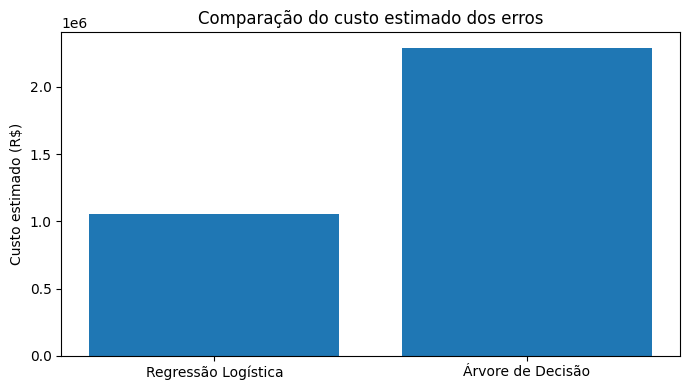

In [118]:
# Gere o gráfico aqui
plt.figure(figsize=(7,4))

plt.bar(custos['Modelo'], custos['Custo estimado (R$)'])

plt.title('Comparação do custo estimado dos erros')
plt.ylabel('Custo estimado (R$)')

plt.tight_layout()
plt.show()

## 17. Escolha da métrica adequada

Responda:
- qual métrica parece mais importante neste caso;
- por quê;
- qual erro traz maior risco operacional.


**Resposta do aluno:**  
- Métrica mais importante:  
- Justificativa:  
- Erro mais crítico:  


## 18. Quadro de decisão com justificativas

Preencha um quadro de decisão resumindo:
- desempenho geral;
- capacidade de detectar falhas críticas;
- controle de alarmes indevidos;
- custo estimado dos erros;
- recomendação preliminar.


In [119]:
# Crie uma tabela chamada quadro_decisao utilizando a função pd.DataFrame().
# Dentro das chaves { }, crie a primeira coluna chamada 'Critério'.
#
# Na coluna 'Critério', informe uma lista contendo os cinco critérios
# que serão utilizados para analisar os modelos:
# 'Desempenho geral'
# 'Capacidade de detectar falhas críticas'
# 'Controle de alarmes indevidos'
# 'Custo estimado dos erros'
# 'Adequação ao contexto industrial'
#
# Crie a segunda coluna chamada 'Elemento de análise'.
#
# Informe uma lista contendo o elemento utilizado para analisar cada critério:
# 'Acurácia e AUC'
# 'Recall'
# 'Precisão'
# 'Falsos positivos e falsos negativos convertidos em custo'
# 'Interpretação técnica integrada'
#
# A primeira posição da coluna 'Elemento de análise' corresponde ao primeiro
# critério da coluna 'Critério', a segunda posição corresponde ao segundo critério,
# e assim por diante.
#
# Na última linha, escreva apenas quadro_decisao para exibir a tabela na tela.
#
# A tabela servirá como um quadro de apoio para organizar quais métricas
# e informações devem ser consideradas na análise dos modelos.

In [120]:
quadro_decisao = pd.DataFrame({
    'Critério': [
        'Desempenho geral',
        'Capacidade de detectar falhas críticas',
        'Controle de alarmes indevidos',
        'Custo estimado dos erros',
        'Adequação ao contexto industrial'
    ],
    'Elemento de análise': [
        'Acurácia e AUC',
        'Recall',
        'Precisão',
        'Falsos positivos e falsos negativos convertidos em custo',
        'Interpretação técnica integrada'
    ]
})

quadro_decisao

,Critério,Elemento de análise
0,Desempenho geral,Acurácia e AUC
1,Capacidade de detectar falhas críticas,Recall
2,Controle de alarmes indevidos,Precisão
3,Custo estimado dos erros,Falsos positivos e falsos negativos convertido...
4,Adequação ao contexto industrial,Interpretação técnica integrada


## Observação

     Custo = FP × CFP ​+ FN × CFN​

Não é um algoritmo padrão do Scikit-Learn nem uma métrica clássica de Machine Learning.

Ele é um exemplo de uma técnica chamada:

>*Cost-Sensitive Evaluation (Avaliação Sensível a Custos) <br>*
>*ou <br>*
>*Cost Matrix (Matriz de Custos)*

A ideia é simples:

Transformar erros estatísticos em impacto financeiro para apoiar decisões de negócio.


## 19. Parecer técnico preliminar

Escreva um parecer técnico curto indicando:
- qual modelo parece mais adequado;
- qual métrica foi priorizada;
- qual o principal argumento para a decisão.


**Parecer técnico preliminar:**  


## 20. Exportação dos resultados

Salve:
- a tabela de métricas;
- a tabela de custos;
- o quadro de decisão.


In [121]:
# Exporte a tabela metricas para um arquivo no formato CSV utilizando .to_csv().
# Informe entre os parênteses o nome do arquivo:
# 'metricas_decisao_aula13.csv'
# O arquivo será criado com esse nome.
# Informe index=False para não salvar o índice numérico da tabela no arquivo.
#
# Exporte a tabela custos para outro arquivo CSV utilizando .to_csv().
# Informe o nome:
# 'custos_erros_aula13.csv'
# Utilize novamente index=False para não incluir o índice da tabela.
#
# Exporte a tabela quadro_decisao para um terceiro arquivo CSV utilizando .to_csv().
# Informe o nome:
# 'quadro_decisao_aula13.csv'
# Utilize novamente index=False para não incluir o índice da tabela.
#
# Utilize print() para mostrar uma mensagem informando que os três arquivos
# foram exportados com sucesso.
# Escreva exatamente:
# 'Arquivos exportados com sucesso.'
#
# Ao executar essa célula, os três arquivos CSV serão salvos
# na pasta de trabalho atual do Python ou Jupyter/Colab.

In [122]:
metricas.to_csv('metricas_modelos.csv', index=False)
custos.to_csv('custos_modelos.csv', index=False)
quadro_decisao.to_csv('quadro_decisao.csv', index=False)

print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 21. Fechamento

Verifique se você:
- relacionou métricas ao custo dos erros;
- interpretou os resultados com coerência técnica;
- comparou modelos considerando impacto operacional;
- estruturou o raciocínio decisório de forma objetiva.
